# Unit 4 – Sequential Flight Delay Analysis Using Markov Models and HMM

**Project:** Machine Learning-Based Flight Delay Prediction and Analysis  
**Unit 4 topics:** Markov models, Hidden Markov Models (HMM), maximum likelihood estimation for HMM, Forward algorithm, Backward algorithm, Sum-Product algorithm, scaling factors and Viterbi algorithm.

> This notebook uses NumPy and Pandas for transparent algorithm implementations. It does not use ready-made HMM or machine-learning estimators. The sequence is built from daily average arrival delay. Hidden states are interpreted as latent low/medium/high operational-delay regimes; they are not directly observed labels.

## 1. Aim and objectives

**Aim:** Model flight-delay patterns as sequential data using Markov chains and Hidden Markov Models.

**Objectives**
- Create a chronological daily sequence from flight records.
- Build a first-order Markov model and estimate transition probabilities by maximum likelihood.
- Implement an HMM with discrete observations.
- Implement Forward, Backward and Sum-Product calculations.
- Use scaling factors to avoid numerical underflow.
- Estimate HMM parameters using the Baum–Welch (EM) algorithm.
- Decode the most likely hidden-state sequence using Viterbi.
- Evaluate the held-out sequence using log-likelihood and prediction accuracy for the observed delay category.

## 2. Mathematical model

### First-order Markov chain
For states \(S_t\), the Markov property is
\[
P(S_t\mid S_{t-1},S_{t-2},\ldots,S_1)=P(S_t\mid S_{t-1}).
\]
The maximum-likelihood transition estimate is
\[
\hat a_{ij}=\frac{N_{ij}}{\sum_j N_{ij}},
\]
where \(N_{ij}\) counts transitions from state \(i\) to state \(j\).

### Hidden Markov Model
An HMM is defined by \(\lambda=(\pi,A,B)\):
- \(\pi_i=P(Z_1=i)\): initial hidden-state probability.
- \(a_{ij}=P(Z_{t+1}=j\mid Z_t=i)\): transition probability.
- \(b_j(o)=P(O_t=o\mid Z_t=j)\): emission probability.

### Forward algorithm
\[
\alpha_t(j)=P(o_1,\ldots,o_t,Z_t=j\mid\lambda)
\]
\[
\alpha_1(j)=\pi_jb_j(o_1),\quad
\alpha_t(j)=b_j(o_t)\sum_i\alpha_{t-1}(i)a_{ij}.
\]

### Backward algorithm
\[
\beta_T(i)=1,\quad
\beta_t(i)=\sum_j a_{ij}b_j(o_{t+1})\beta_{t+1}(j).
\]

### Sum-Product / posterior state probability
\[
\gamma_t(i)=\frac{\alpha_t(i)\beta_t(i)}{P(O\mid\lambda)}.
\]
The forward-backward procedure is an instance of the sum-product algorithm on the HMM chain.

### Viterbi algorithm
Viterbi replaces summation by maximisation to find the single most probable hidden-state path.

## 3. Load flight data and create a daily sequence

Attach the same `flights.csv` file in Kaggle. Daily mean arrival delay is converted into three observation symbols using quantile cut points. Dates are sorted chronologically.

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
files = glob.glob('/kaggle/input/**/flights.csv', recursive=True)
if not files:
    raise FileNotFoundError("flights.csv not found. In Kaggle, click Add Data and attach the flight dataset.")

path = files[0]
print("Using:", path)

needed = ["YEAR", "MONTH", "DAY", "ARRIVAL_DELAY"]
df = pd.read_csv(path, usecols=lambda c: c in needed, low_memory=False)
missing = [c for c in needed if c not in df.columns]
if missing:
    raise ValueError("Required columns missing: " + str(missing))

df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=needed).copy()
df["DATE"] = pd.to_datetime(dict(year=df.YEAR.astype(int),
                                month=df.MONTH.astype(int),
                                day=df.DAY.astype(int)), errors="coerce")
df = df.dropna(subset=["DATE"])

daily = (df.groupby("DATE")["ARRIVAL_DELAY"]
         .agg(["mean", "median", "count"])
         .reset_index()
         .sort_values("DATE")
         .reset_index(drop=True))
print("Number of daily observations:", len(daily))
display(daily.head())

Using: /kaggle/input/datasets/usdot/flight-delays/flights.csv
Number of daily observations: 365


,DATE,mean,median,count
0,2015-01-01,5.352496,-3.0,13464
1,2015-01-02,9.838904,1.0,16456
2,2015-01-03,25.461860,11.0,15050
3,2015-01-04,31.975011,14.0,15887
4,2015-01-05,18.811310,4.0,16074


## 4. Convert continuous daily delays into observation symbols

Symbols are defined by tertiles of daily mean arrival delay. The mapping is 0 = Low, 1 = Medium, 2 = High. This discretisation allows us to use a categorical-emission HMM.

Tertile cut points: 0.06 6.46
Observation counts: [122 121 122]


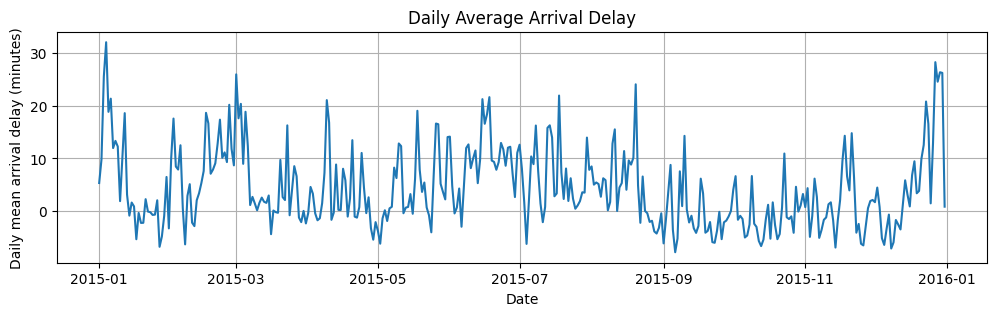

In [2]:
q1, q2 = daily["mean"].quantile([1/3, 2/3]).to_numpy()
def to_symbol(x):
    if x <= q1:
        return 0
    elif x <= q2:
        return 1
    return 2

daily["OBSERVATION"] = daily["mean"].apply(to_symbol).astype(int)
obs = daily["OBSERVATION"].to_numpy()
symbol_names = ["Low-delay day", "Medium-delay day", "High-delay day"]

print("Tertile cut points:", round(q1, 3), round(q2, 3))
print("Observation counts:", np.bincount(obs, minlength=3))
plt.figure(figsize=(12,3))
plt.plot(daily["DATE"], daily["mean"])
plt.xlabel("Date")
plt.ylabel("Daily mean arrival delay (minutes)")
plt.title("Daily Average Arrival Delay")
plt.grid(True)
plt.show()

## 5. Markov chain – maximum likelihood transition estimation

For this first model, the observed delay categories themselves are treated as Markov states. This gives a baseline sequence model.

In [3]:
def estimate_markov_chain(sequence, n_states):
    counts = np.zeros((n_states, n_states), dtype=float)
    for t in range(len(sequence)-1):
        counts[sequence[t], sequence[t+1]] += 1
    # Add-one smoothing avoids zero-probability transitions
    A = counts + 1.0
    A = A / A.sum(axis=1, keepdims=True)
    pi_counts = np.bincount(sequence[:-1], minlength=n_states).astype(float) + 1
    pi = pi_counts / pi_counts.sum()
    return pi, A, counts

split = max(2, int(0.8*len(obs)))
train_obs, test_obs = obs[:split], obs[split:]
markov_pi, markov_A, markov_counts = estimate_markov_chain(train_obs, 3)
print("Transition counts (training):")
display(pd.DataFrame(markov_counts, index=symbol_names, columns=symbol_names))
print("Smoothed transition matrix:")
display(pd.DataFrame(markov_A, index=symbol_names, columns=symbol_names))

Transition counts (training):


,Low-delay day,Medium-delay day,High-delay day
Low-delay day,56.0,27.0,8.0
Medium-delay day,26.0,41.0,27.0
High-delay day,10.0,25.0,71.0


Smoothed transition matrix:


,Low-delay day,Medium-delay day,High-delay day
Low-delay day,0.606383,0.297872,0.095745
Medium-delay day,0.278351,0.432990,0.288660
High-delay day,0.100917,0.238532,0.660550


## 6. Markov-chain next-symbol prediction

Predict the next observed category as the most likely transition from the current category. Evaluate on the chronological test segment.

In [4]:
def markov_predict(sequence, A):
    return np.array([np.argmax(A[sequence[t]]) for t in range(len(sequence)-1)])

if len(test_obs) >= 2:
    pred = markov_predict(test_obs, markov_A)
    actual = test_obs[1:]
    markov_accuracy = np.mean(pred == actual)
    print("Markov next-symbol accuracy:", round(markov_accuracy, 4))
else:
    markov_accuracy = np.nan
    print("Not enough test observations for next-symbol accuracy.")

Markov next-symbol accuracy: 0.6389


## 7. HMM setup and numerical utilities

We use three hidden states and three observed symbols. Hidden states are latent regimes; their names are assigned only after inspecting the fitted emission probabilities. The following functions implement the HMM directly.

In [5]:
def normalise_rows(M):
    M = np.maximum(M, 1e-12)
    return M / M.sum(axis=1, keepdims=True)

def initialise_hmm(n_states=3, n_symbols=3, seed=42):
    rng = np.random.default_rng(seed)
    pi = np.ones(n_states) / n_states
    A = normalise_rows(rng.random((n_states, n_states)) + 0.5)
    B = normalise_rows(rng.random((n_states, n_symbols)) + 0.5)
    return pi, A, B

pi, A, B = initialise_hmm()
print("Initial distribution:", pi)
print("Initial transition matrix:\n", np.round(A, 3))
print("Initial emission matrix:\n", np.round(B, 3))

Initial distribution: [0.33333333 0.33333333 0.33333333]
Initial transition matrix:
 [[0.357 0.263 0.38 ]
 [0.366 0.182 0.452]
 [0.397 0.405 0.198]]
Initial emission matrix:
 [[0.293 0.268 0.439]
 [0.335 0.388 0.277]
 [0.31  0.45  0.24 ]]


## 8. Forward algorithm with scaling factors

At each time step, the unscaled forward values are normalised by a scaling factor \(c_t\). The sequence log-likelihood is \(-\sum_t\log c_t\) under this convention.

In [6]:
def forward_scaled(sequence, pi, A, B):
    T = len(sequence)
    K = len(pi)
    alpha = np.zeros((T, K))
    scales = np.zeros(T)

    alpha[0] = pi * B[:, sequence[0]]
    scales[0] = alpha[0].sum()
    scales[0] = max(scales[0], 1e-300)
    alpha[0] /= scales[0]

    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A) * B[:, sequence[t]]
        scales[t] = max(alpha[t].sum(), 1e-300)
        alpha[t] /= scales[t]

    log_likelihood = np.sum(np.log(scales))
    return alpha, scales, log_likelihood

alpha, scales, train_log_likelihood = forward_scaled(train_obs, pi, A, B)
print("Initial HMM training log-likelihood:", round(train_log_likelihood, 4))
print("First five scaled forward rows:\n", np.round(alpha[:5], 4))

Initial HMM training log-likelihood: -321.7554
First five scaled forward rows:
 [[0.2425 0.3509 0.4067]
 [0.5076 0.2481 0.2443]
 [0.5006 0.2371 0.2624]
 [0.501  0.2398 0.2591]
 [0.501  0.2393 0.2598]]


## 9. Backward algorithm with scaling

The backward recursion uses the same scaling factors as the forward pass. The posterior state probabilities are obtained by normalising the elementwise product of forward and backward messages.

In [7]:
def backward_scaled(sequence, A, B, scales):
    T = len(sequence)
    K = A.shape[0]
    beta = np.zeros((T, K))
    beta[-1] = 1.0 / scales[-1]

    for t in range(T-2, -1, -1):
        beta[t] = A @ (B[:, sequence[t+1]] * beta[t+1])
        beta[t] /= scales[t]

    return beta

beta = backward_scaled(train_obs, A, B, scales)
gamma = alpha * beta
gamma /= gamma.sum(axis=1, keepdims=True)
print("First five backward rows:\n", np.round(beta[:5], 4))
print("First five posterior state probabilities (gamma):\n", np.round(gamma[:5], 4))

First five backward rows:
 [[2.6756 2.6726 2.7713]
 [3.0428 3.0395 3.1517]
 [3.06   3.0566 3.1695]
 [3.058  3.0546 3.1675]
 [3.0584 3.0552 3.1675]]
First five posterior state probabilities (gamma):
 [[0.2391 0.3456 0.4153]
 [0.5034 0.2458 0.2509]
 [0.496  0.2347 0.2693]
 [0.4965 0.2374 0.266 ]
 [0.4965 0.2369 0.2666]]


## 10. Sum-Product algorithm

The forward-backward calculation is the sum-product algorithm on a chain: messages are multiplied by local emission/transition factors and summed over hidden states. The resulting `gamma` gives the posterior probability of each hidden state at each time.

In [8]:
print("Posterior probabilities sum to 1 at each time:",
      np.allclose(gamma.sum(axis=1), 1.0))
posterior_states = gamma.argmax(axis=1)
print("Most probable posterior state counts:",
      np.bincount(posterior_states, minlength=3))

Posterior probabilities sum to 1 at each time: True
Most probable posterior state counts: [185   0 107]


## 11. Maximum-likelihood HMM parameter estimation – Baum–Welch

Baum–Welch is an EM algorithm. The E-step computes posterior state probabilities (gamma) and posterior transition probabilities (xi). The M-step updates initial, transition and emission probabilities.

Baum-Welch iterations: 97
Final training log-likelihood: -257.4677
Estimated initial probabilities: [0. 0. 1.]
Estimated transition matrix:
 [[0.8148 0.     0.1852]
 [0.0142 0.9803 0.0055]
 [0.2107 0.0474 0.742 ]]
Estimated emission matrix:
 [[0.     0.0538 0.9462]
 [0.6181 0.237  0.1449]
 [0.1909 0.8091 0.    ]]


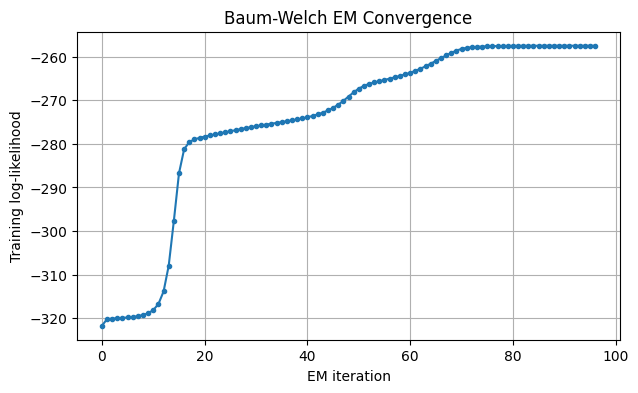

In [9]:
def baum_welch(sequence, n_states=3, n_symbols=3, max_iter=100, tol=1e-4, seed=42):
    pi, A, B = initialise_hmm(n_states, n_symbols, seed)
    history = []

    for iteration in range(max_iter):
        alpha, scales, ll = forward_scaled(sequence, pi, A, B)
        beta = backward_scaled(sequence, A, B, scales)

        gamma = alpha * beta
        gamma /= gamma.sum(axis=1, keepdims=True)

        xi_sum = np.zeros((n_states, n_states))
        for t in range(len(sequence)-1):
            xi = (alpha[t, :, None] * A *
                  (B[:, sequence[t+1]] * beta[t+1])[None, :])
            denom = xi.sum()
            if denom > 0:
                xi_sum += xi / denom

        pi_new = gamma[0] + 1e-8
        pi_new /= pi_new.sum()

        A_new = xi_sum + 1e-6
        A_new /= A_new.sum(axis=1, keepdims=True)

        B_new = np.zeros_like(B)
        for j in range(n_states):
            for symbol in range(n_symbols):
                B_new[j, symbol] = gamma[sequence == symbol, j].sum()
        B_new += 1e-6
        B_new /= B_new.sum(axis=1, keepdims=True)

        history.append(ll)
        pi, A, B = pi_new, A_new, B_new

        if iteration > 0 and abs(history[-1] - history[-2]) < tol:
            break

    return pi, A, B, history

pi_hat, A_hat, B_hat, ll_history = baum_welch(train_obs, max_iter=100)
print("Baum-Welch iterations:", len(ll_history))
print("Final training log-likelihood:", round(ll_history[-1], 4))
print("Estimated initial probabilities:", np.round(pi_hat, 4))
print("Estimated transition matrix:\n", np.round(A_hat, 4))
print("Estimated emission matrix:\n", np.round(B_hat, 4))

plt.figure(figsize=(7,4))
plt.plot(ll_history, marker=".")
plt.xlabel("EM iteration")
plt.ylabel("Training log-likelihood")
plt.title("Baum-Welch EM Convergence")
plt.grid(True)
plt.show()

## 12. Viterbi algorithm – most likely hidden-state path

Viterbi uses dynamic programming in log space to avoid numerical underflow. It returns the single most likely sequence of hidden states for the observations.

In [10]:
def viterbi(sequence, pi, A, B):
    T = len(sequence)
    K = len(pi)
    logA = np.log(np.maximum(A, 1e-300))
    logB = np.log(np.maximum(B, 1e-300))
    logpi = np.log(np.maximum(pi, 1e-300))

    delta = np.zeros((T, K))
    psi = np.zeros((T, K), dtype=int)
    delta[0] = logpi + logB[:, sequence[0]]

    for t in range(1, T):
        for j in range(K):
            scores = delta[t-1] + logA[:, j]
            psi[t, j] = np.argmax(scores)
            delta[t, j] = np.max(scores) + logB[j, sequence[t]]

    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(delta[-1])
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path, np.max(delta[-1])

train_path, best_log_prob = viterbi(train_obs, pi_hat, A_hat, B_hat)
print("Viterbi path (first 30 states):", train_path[:30])
print("Viterbi state counts:", np.bincount(train_path, minlength=3))

Viterbi path (first 30 states): [2 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Viterbi state counts: [ 94 127  71]


## 13. Interpret hidden states

Hidden-state labels are arbitrary (state 0 is not automatically 'low'). Inspect the emission probabilities to understand which observation symbol each state most often emits.

In [11]:
emission_table = pd.DataFrame(B_hat, columns=symbol_names,
                              index=[f"Hidden state {i}" for i in range(len(pi_hat))])
display(emission_table.round(4))
for i, row in emission_table.iterrows():
    print(i, "most often emits:", row.idxmax())

,Low-delay day,Medium-delay day,High-delay day
Hidden state 0,0.0000,0.0538,0.9462
Hidden state 1,0.6181,0.2370,0.1449
Hidden state 2,0.1909,0.8091,0.0000


Hidden state 0 most often emits: High-delay day
Hidden state 1 most often emits: Low-delay day
Hidden state 2 most often emits: Medium-delay day


## 14. Held-out sequence evaluation

The HMM is fitted only on the first 80% of the chronological sequence. We evaluate the likelihood of the held-out observations under the fitted model and decode the test hidden-state path. Hidden states have no ground-truth labels, so Viterbi hidden-state accuracy cannot be calculated from this dataset.

In [12]:
if len(test_obs):
    _, _, test_ll = forward_scaled(test_obs, pi_hat, A_hat, B_hat)
    test_path, test_best_logprob = viterbi(test_obs, pi_hat, A_hat, B_hat)
    print("Held-out test log-likelihood:", round(test_ll, 4))
    print("Held-out observations:", len(test_obs))
    print("Test Viterbi state counts:", np.bincount(test_path, minlength=3))
    print("Mean test log-likelihood per day:", round(test_ll/len(test_obs), 4))
else:
    print("No held-out observations. Increase the available date range.")

Held-out test log-likelihood: -73.006
Held-out observations: 73
Test Viterbi state counts: [12 53  8]
Mean test log-likelihood per day: -1.0001


## 15. Markov chain versus HMM

The Markov baseline predicts the next observed delay category directly. The HMM instead assumes observations are generated by hidden states. Compare their held-out sequence likelihoods cautiously: they are different model formulations and the Markov accuracy is not directly comparable to HMM log-likelihood.

In [13]:
print("Markov next-observation accuracy:", round(markov_accuracy, 4)
      if np.isfinite(markov_accuracy) else "not available")
print("HMM held-out log-likelihood:", round(test_ll, 4)
      if len(test_obs) else "not available")
print("HMM held-out mean log-likelihood per observation:",
      round(test_ll/len(test_obs), 4) if len(test_obs) else "not available")

Markov next-observation accuracy: 0.6389
HMM held-out log-likelihood: -73.006
HMM held-out mean log-likelihood per observation: -1.0001


## 16. Result and conclusion

Fill this section using the printed values after running the notebook.

**Conclusion template:** A first-order Markov chain was used to model transitions among daily delay categories. A discrete HMM was then fitted to represent latent operational regimes. The Forward and Backward algorithms calculated sequence probabilities and posterior state probabilities; the Sum-Product procedure combined these messages; scaling factors controlled numerical underflow; Baum–Welch estimated model parameters; and Viterbi decoded the most likely hidden-state sequence. The held-out log-likelihood provides a measure of how well the fitted HMM explains unseen observation sequences.

## 17. Limitations and review notes

- The daily sequence is based on daily mean arrival delay, not individual flight-level sequences.
- Observation symbols are created using training-independent full-sequence tertile cut points for simple exploration. For a strict forecasting experiment, calculate cut points from training data only and apply them to test data.
- The hidden states are latent statistical regimes; they are not confirmed real-world operational causes.
- Baum–Welch can converge to local optima and depends on initialisation.
- Hidden-state identities are permutation-invariant; state numbers have no fixed meaning.
- A single year of daily observations is a short sequence, so interpret estimated transitions cautiously.